In [ ]:
import re
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, callbacks

print(tf.config.list_physical_devices("GPU"))   # should show a GPU

VOCAB_SIZE = 20000
MAX_LEN = 400
EMBED_DIM = 128
BATCH_SIZE = 64
EPOCHS = 5
SEED = 42
tf.keras.utils.set_random_seed(SEED)

[]


In [ ]:
df = pd.read_csv("IMDB_Dataset.csv")
df = df.drop_duplicates()

# keep 1/4 of the data, with equal positive/negative proportions preserved
df = df.groupby("sentiment").sample(frac=0.25, random_state=SEED)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)       # remove <br /> tags
    text = re.sub(r"[^a-z' ]+", " ", text)   # remove digits and punctuation
    return re.sub(r"\s+", " ", text).strip()

df["review"] = df["review"].apply(clean_text)
df["label"] = (df["sentiment"] == "positive").astype(int)
print(df.shape)
print(df["label"].value_counts())   # should be nearly 50/50
df.head()

(12395, 3)
label
1    6221
0    6174
Name: count, dtype: int64


,review,sentiment,label
32953,i usually much prefer french movies over ameri...,negative,0
24703,this movie lacked everything story acting surp...,negative,0
26689,bonjour tristesse covers similar ground as 'th...,negative,0
8908,'blue desert' may have had the potential to be...,negative,0
2925,the writer director of this film obviously doe...,negative,0


In [ ]:
texts = np.array(df["review"].tolist(), dtype=str)
labels = df["label"].to_numpy(dtype="float32")

x_train, x_tmp, y_train, y_tmp = train_test_split(
    texts, labels, test_size=0.2, stratify=labels, random_state=SEED)
x_val, x_test, y_val, y_test = train_test_split(
    x_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

print(len(x_train), len(x_val), len(x_test))

9916 1239 1240


In [ ]:
vectorizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE, output_mode="int", output_sequence_length=MAX_LEN)
vectorizer.adapt(x_train)
print(vectorizer.get_vocabulary()[:10])

['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('in'), np.str_('it')]


In [ ]:
def build_model():
    model = models.Sequential([
        layers.Input(shape=(1,), dtype=tf.string),
        vectorizer,
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.SpatialDropout1D(0.3),
        layers.Bidirectional(layers.LSTM(64, dropout=0.2)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

bilstm_model = build_model()
bilstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 400)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_3 (Embedding)         │ (None, 400, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_3             │ (None, 400, 128)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,667,137 (10.17 MB)

 Trainable params: 2,667,137 (10.17 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1),
]

# Convert inputs to NumPy object arrays to avoid Keras fixed-width string dtype parsing errors
x_train_fixed = np.array(x_train, dtype=object)
x_val_fixed = np.array(x_val, dtype=object)
x_test_fixed = np.array(x_test, dtype=object)

history = bilstm_model.fit(
    x_train_fixed, y_train,
    validation_data=(x_val_fixed, y_val),
    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=cbs)

loss, acc = bilstm_model.evaluate(x_test_fixed, y_test, verbose=0)
print(f"\nBiLSTM test accuracy = {acc:.4f}")

Epoch 1/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.7386 - loss: 0.5299 - val_accuracy: 0.8458 - val_loss: 0.3526 - learning_rate: 0.0010
Epoch 2/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.9012 - loss: 0.2571 - val_accuracy: 0.8620 - val_loss: 0.3286 - learning_rate: 0.0010
Epoch 3/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 201s 1s/step - accuracy: 0.9438 - loss: 0.1598 - val_accuracy: 0.8636 - val_loss: 0.3560 - learning_rate: 0.0010
Epoch 4/5
155/155 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.9765 - loss: 0.0735 - val_accuracy: 0.8684 - val_loss: 0.3835 - learning_rate: 5.0000e-04

BiLSTM test accuracy = 0.8573


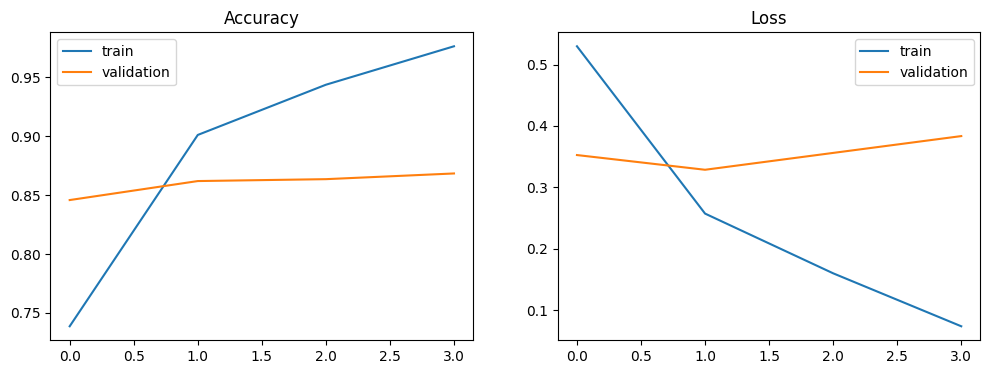

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

In [ ]:
def predict(model, review):
    input_data = np.array([clean_text(review)], dtype=object)
    p = float(model.predict(input_data, verbose=0)[0][0])
    print(f"{p:.3f} -> {'positive' if p > 0.5 else 'negative'}")

predict(bilstm_model, "An absolute masterpiece, I loved every minute.")
predict(bilstm_model, "Boring, predictable and a complete waste of time.")

0.562 -> positive
0.012 -> negative


In [ ]:
# @title Interactive Sentiment Predictor
# Enter a review below and run this cell to see the prediction!

user_review = "its not good as they said" #@param {type:"string"}

if user_review.strip() == "":
    print("Please enter a valid review.")
else:
    print(f"Review: \"{user_review}\"\nPrediction:")

    # Check if dependencies are defined in the global scope
    if 'predict' not in globals():
        print("Error: The 'predict' function is not defined. Please run cell z8giivNDArEz first.")
    elif 'bilstm_model' not in globals():
        print("Error: 'bilstm_model' is not defined. Please run cell Zs4K65OqAkqL to train the model first.")
    else:
        predict(bilstm_model, user_review)

Review: "its not good as they said"
Prediction:
0.440 -> negative
